# EDA — Dataset chấm điểm & phản hồi bài lập trình

Hai nguồn dữ liệu:
- `sample_dataset` (32 mẫu, **có nhãn**) — dùng để hiểu định dạng và làm few-shot exemplar.
- `public_test_release` (328 mẫu, **không có nhãn**) — tập dev thật để nộp `predictions.json` lên leaderboard (giới hạn 2 lượt/ngày).

Lưu ý: đây chưa phải tập train/test chính thức đầy đủ; `sample_dataset` là tập mẫu nhỏ nên một số phân phối nhãn bị lệch do kích thước mẫu.

In [1]:
import sys, json
from collections import Counter
import matplotlib.pyplot as plt

sys.path.insert(0, "../src")
from data import load_sample_dataset, load_public_test, read_code

ds_sample = load_sample_dataset()
ds_public = load_public_test()
RUBRIC_DIMS = ["compilable", "io_format", "logic", "edge_case", "complexity", "code_quality"]

print("sample_dataset:", {k: len(v) for k, v in ds_sample.tasks.items()})
print("public_test   :", {k: len(v) for k, v in ds_public.tasks.items()})


sample_dataset: {1: 32, 2: 32, 3: 32}
public_test   : {1: 328, 2: 328, 3: 328}


## Task 1 — Phân phối rubric & tổng điểm (sample_dataset, có nhãn)

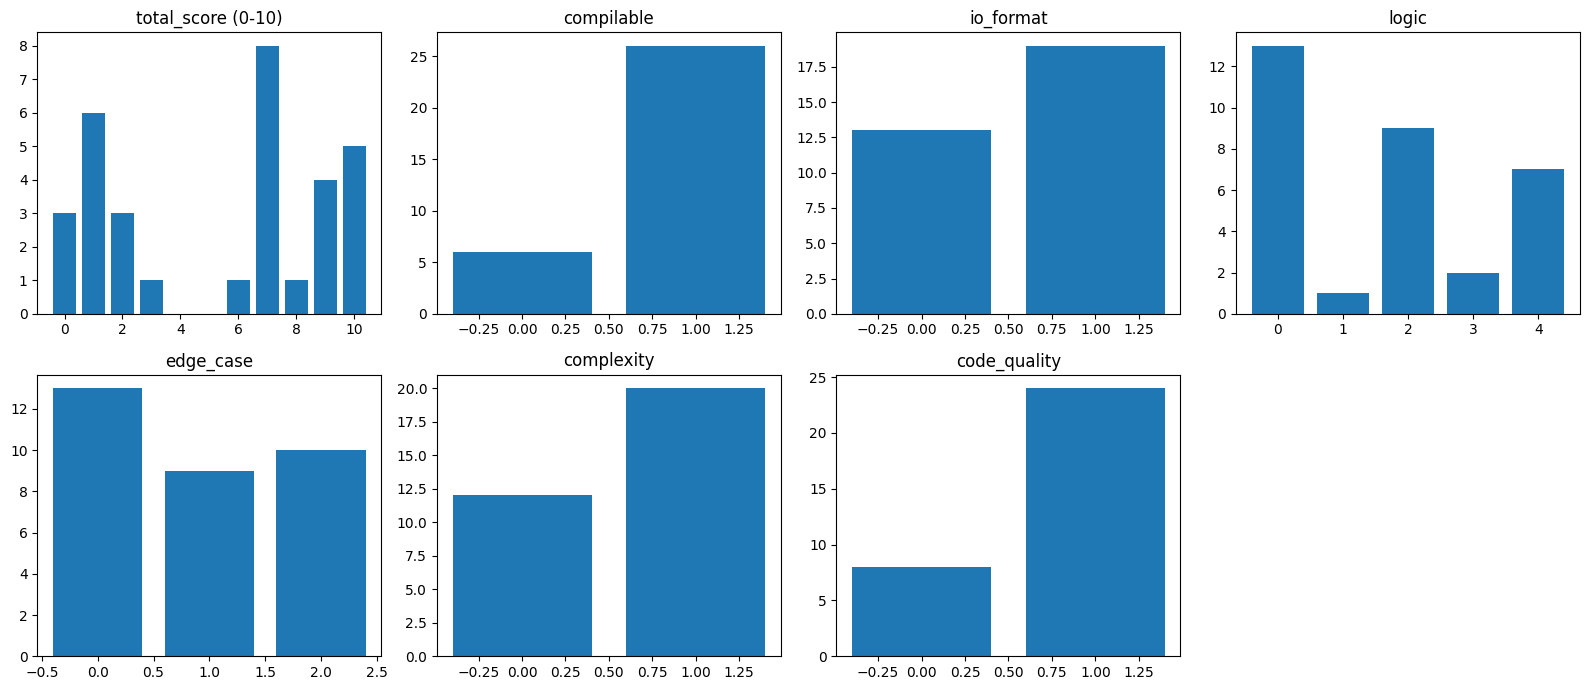

In [2]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
axes = axes.flatten()

total_scores = [s["output"]["total_score"] for s in ds_sample.tasks[1]]
axes[0].bar(*zip(*sorted(Counter(total_scores).items())))
axes[0].set_title("total_score (0-10)")

for i, d in enumerate(RUBRIC_DIMS, start=1):
    vals = [s["output"]["rubric"][d] for s in ds_sample.tasks[1]]
    c = sorted(Counter(vals).items())
    axes[i].bar(*zip(*c))
    axes[i].set_title(d)

for ax in axes[len(RUBRIC_DIMS) + 1:]:
    ax.axis("off")
plt.tight_layout()
plt.savefig("../reports/task1_rubric_dist.png", dpi=100)
plt.show()


**Nhận xét:** `compilable` lệch mạnh về 1 (26/32), `logic` có đỉnh tại 0 (13/32) — nhiều bài không làm được gì về logic.
Rubric 6 chiều có phân phối không đều giữa các mức, QWK sẽ nhạy với các mẫu ở đuôi phân phối (0 hoặc 10 điểm).

## Task 2 — Phân phối nhãn lỗi (đa nhãn, sample_dataset)

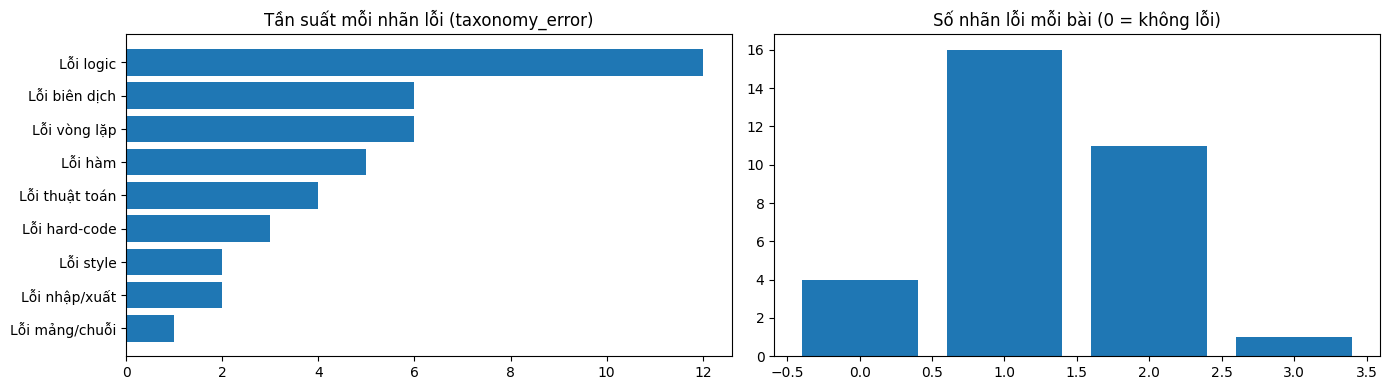

Nhãn KHÔNG xuất hiện trong sample_dataset: {'Lỗi edge case'}


In [3]:
label_count = Counter()
n_labels_per_sample = Counter()
for s in ds_sample.tasks[2]:
    labels = s["output"]["taxonomy_error"]
    n_labels_per_sample[len(labels)] += 1
    for l in labels:
        label_count[l] += 1

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
labels, counts = zip(*label_count.most_common())
axes[0].barh(labels, counts)
axes[0].invert_yaxis()
axes[0].set_title("Tần suất mỗi nhãn lỗi (taxonomy_error)")

axes[1].bar(*zip(*sorted(n_labels_per_sample.items())))
axes[1].set_title("Số nhãn lỗi mỗi bài (0 = không lỗi)")
plt.tight_layout()
plt.savefig("../reports/task2_label_dist.png", dpi=100)
plt.show()

full_label_space = ds_sample.label_space["taxonomy_error"]
absent = set(full_label_space) - set(label_count)
print("Nhãn KHÔNG xuất hiện trong sample_dataset:", absent)


**Nhận xét quan trọng:** `Lỗi logic` xuất hiện nhiều nhất (12/32), `Lỗi mảng/chuỗi` chỉ 1 lần, và **`Lỗi edge case` không xuất hiện trong sample_dataset**.
Đây là lý do macro-F1 được chọn làm metric chính (phạt nặng việc chỉ đoán nhãn phổ biến) — nhưng cũng có nghĩa là
**một oracle dự đoán đúng 100% trên sample_dataset vẫn chỉ đạt macro-F1 ≈ 0.9** (xem notebook 02), vì theo quy ước macro-F1,
một nhãn không xuất hiện cả ở gold và pred được tính F1 = 0, kéo điểm trung bình xuống dù dự đoán hoàn hảo.
Đây là một phát hiện đáng lưu ý cho phần ablation/phân tích lỗi — và là ứng viên cho điểm thưởng (hạn chế của metric trên tập mẫu nhỏ/lệch).

## Task 3 — Mức phản hồi yêu cầu (`target_feedback_level`)

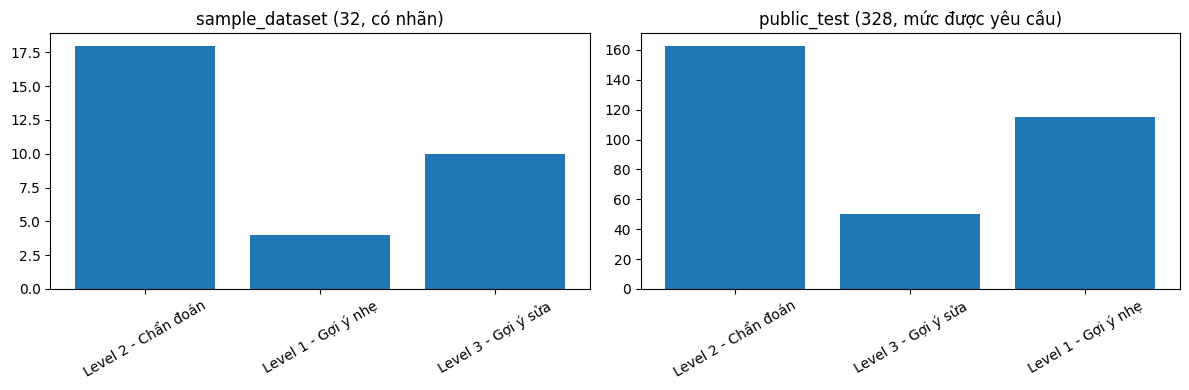

sample_dataset levels: {'Level 2 - Chẩn đoán': 18, 'Level 1 - Gợi ý nhẹ': 4, 'Level 3 - Gợi ý sửa': 10}
public_test  levels: {'Level 2 - Chẩn đoán': 163, 'Level 3 - Gợi ý sửa': 50, 'Level 1 - Gợi ý nhẹ': 115}


In [4]:
level_sample = Counter(s["input"]["target_feedback_level"] for s in ds_sample.tasks[3])
level_public = Counter(s["input"]["target_feedback_level"] for s in ds_public.tasks[3])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(level_sample.keys(), level_sample.values())
axes[0].set_title("sample_dataset (32, có nhãn)")
axes[0].tick_params(axis="x", rotation=30)

axes[1].bar(level_public.keys(), level_public.values())
axes[1].set_title("public_test (328, mức được yêu cầu)")
axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.savefig("../reports/task3_level_dist.png", dpi=100)
plt.show()

print("sample_dataset levels:", dict(level_sample))
print("public_test  levels:", dict(level_public))


**Nhận xét:** **Level 4 (lời giải mẫu) không xuất hiện** ở cả sample_dataset lẫn 328 mẫu public_test —
nghĩa là chúng ta **không có exemplar nào cho Level 4** để làm few-shot, và cũng không bị chấm compliance ở mức này
trong tập public test hiện có. Cần lưu ý trong report: hành vi ở Level 4 chưa được kiểm chứng bằng dữ liệu thật.

## Chất lượng dữ liệu — `compile_log` và breakdown theo exam

In [5]:
nonempty_sample = sum(1 for s in ds_sample.tasks[1] if (s["input"].get("compile_log") or "").strip())
nonempty_public = sum(1 for s in ds_public.tasks[1] if (s["input"].get("compile_log") or "").strip())
print(f"compile_log non-empty: sample_dataset {nonempty_sample}/32, public_test {nonempty_public}/328")

exam_breakdown = Counter((ds_public.exams[s["input"]["exam_id"]]["exam_id"],
                          ds_public.exams[s["input"]["exam_id"]]["exam_type"]) for s in ds_public.tasks[1])
print("public_test exam breakdown:", dict(exam_breakdown))


compile_log non-empty: sample_dataset 0/32, public_test 0/328
public_test exam breakdown: {('Class03-Final-1', 'single_problem'): 73, ('Class03-Midterm-1', 'single_problem'): 58, ('Class03-Midterm-2', 'single_problem'): 73, ('Class01-Test1', 'multi_problem'): 31, ('Class01-Test2', 'multi_problem'): 43, ('Class02-Test1', 'multi_problem'): 50}


**Phát hiện:** `compile_log` rỗng cho TẤT CẢ 360 mẫu (32 + 328) hiện có — trường này tồn tại trong schema nhưng
chưa được điền trong dữ liệu đã phát. Tín hiệu phụ README mô tả (`compiles_locally` vs nhãn `compilable`) không thể
kiểm chứng trên dữ liệu hiện tại; sẽ cần kiểm tra lại khi có tập train/test đầy đủ.

`public_test` có 2 loại đề: `multi_problem` (Class01-Test1/2, Class02-Test1 — có ràng buộc tiên quyết giữa các câu)
và `single_problem` (Class03-Midterm-1/2, Class03-Final-1 — có hidden testcases). Pipeline chấm phải tôn trọng
chính sách tiên quyết riêng cho từng exam_id, lấy từ `exams.json["grading_policy"]`, không thể hard-code.

## Tóm tắt các phát hiện chính

1. **Mất cân bằng nhãn** rõ rệt ở cả 3 task — biện minh cho việc chọn QWK/macro-F1 làm metric chính thay vì accuracy.
2. **`Lỗi edge case` và Level 4** hoàn toàn vắng mặt trong dữ liệu hiện có → macro-F1 có sàn thấp hơn 1.0 ngay cả với oracle; Level 4 chưa được kiểm chứng.
3. **`compile_log` luôn rỗng** trong dữ liệu đã phát (360/360) — tín hiệu phụ README đề cập chưa dùng được, cần xác nhận lại với tập dữ liệu đầy đủ.
4. **Chính sách tiên quyết** (multi_problem) khác nhau giữa các exam — phải đọc từ `exams.json`, không hard-code theo đề cụ thể.
5. Đây là các ứng viên cho phần **phân tích lỗi** và **điểm thưởng chất lượng dữ liệu/metric** của đồ án.